# Final fitted GMM emissions: component distributions across the M sweep

Inputs (read-only, from the sweep run):

- `notebooks/sp500/results/gmm_sweep_2004_2013/checkpoint.pkl` - final refresh checkpoint, 8 branches (`gmm2_pca` ... `gmm5_no_pca`)
- `notebooks/sp500/results/gmm_sweep_2004_2013/signals.csv` - decision dates and run settings
- `data/processed/sp500_index_price.csv` - prices for the return axis units

Run that produced it: `run_paper_regime.py --models gmm2_pca gmm2_no_pca gmm3_pca gmm3_no_pca gmm4_pca gmm4_no_pca gmm5_pca gmm5_no_pca --years 5 --start 2004-01-02 --end 2013-12-31 --max-iter 100 --update-iter 3 --refresh-days 63`, seed 0.

Definitions used below:

- The HMM always has **2 states**; $M$ is the number of Gaussian components **inside each state** (emission shapes `(K, M, D)`). Blue = the bull state by the mean-return label, red = bear.
- **Histogram bars**: the model's own training observations, binned per state with each day $t$ weighted by its filtered posterior $\hat p_t(k) = P(s_t = k \mid x_1, \dots, x_t)$, normalized to integrate to 1. Bars show the empirical distribution each state's mixture is fitted to. Edge spikes at the axis limits are clipped tails.
- **Curves**: the fitted mixture $\sum_j w_j\,\mathcal{N}(\mu_j, \sigma_j)$ for that state.
- **Symmetry residual**: $\max_x |f(c+x) - f(c-x)| / \max f$ with $c$ the mixture mean; 0 means the fitted density is symmetric about its mean.
- **KS** compares the fitted mixture CDF with the filtered-posterior-weighted empirical CDF on the same training data. It measures in-sample shape recovery, not out-of-sample quality.


In [1]:
from pathlib import Path
import pickle
import sys

import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks" / "sp500"))
from paper_regime_experiment import build_observations, label_bull

RES = ROOT / "notebooks/sp500/results/gmm_sweep_2004_2013"
state = pickle.load((RES / "checkpoint.pkl").open("rb"))
signals = pd.read_csv(RES / "signals.csv", parse_dates=["date"])
prices = pd.read_csv(ROOT / "data/processed/sp500_index_price.csv",
                     parse_dates=["YYYYMMDD"]).set_index("YYYYMMDD")["DlyPrcInd"]
prices = prices.sort_index().astype(float)
features = build_observations(prices).dropna()
returns = prices.pct_change(fill_method=None)

# Rebuild the training window of the final refresh: 5-year initial window,
# expanding history to the last decision date (run_paper_regime.py semantics).
start = pd.Timestamp(signals.loc[signals.refresh, "date"].min())
years = 5
initial = features.loc[(features.index > start - pd.DateOffset(years=years))
                       & (features.index <= start)].index
hist = features.loc[initial[0]:signals.date.max()].index
daily = returns.reindex(hist).to_numpy()
print(f"window {hist[0].date()} to {hist[-1].date()}  n={len(hist)}  "
      f"(signals.csv max training_days = {signals.training_days.max()})")
print(f"empirical daily return: mean {100*daily.mean():.3f}%  sd {100*daily.std(ddof=1):.2f}%  "
      f"skew {pd.Series(daily).skew():.2f}  kurtosis {pd.Series(daily).kurt():.1f}")

SPEC_ORDER = sorted(state["branches"], key=lambda key: (int(key[3]), key))


def mixture_stats(w, mu, sd):
    """Mean, sd, skewness, and excess kurtosis of a Gaussian mixture (1-D)."""
    mean = (w * mu).sum()
    var = (w * (sd**2 + mu**2)).sum() - mean**2
    m3 = (w * (mu**3 + 3 * mu * sd**2)).sum()
    c3 = m3 - 3 * mean * var - mean**3
    m4 = (w * (mu**4 + 6 * mu**2 * sd**2 + 3 * sd**4)).sum()
    c4 = m4 - 4 * mean * m3 + 6 * mean**2 * (var + mean**2) - 3 * mean**4
    return mean, np.sqrt(var), c3 / var**1.5, c4 / var**2 - 3


def sym_residual(w, mu, sd, c, half):
    """Peak-normalized max of |f(c+x) - f(c-x)|; 0 means symmetric about c."""
    g = np.linspace(0.0, half, 1201)
    f = lambda x: sum(w[j] * norm.pdf(c + x, mu[j], sd[j]) for j in range(len(w)))
    fp = np.array([f(x) for x in g])
    fm = np.array([f(-x) for x in g])
    return float(np.max(np.abs(fp - fm)) / max(fp.max(), fm.max()))


diag_rows, comp_rows, curves = [], [], {}
for key, (model, scaler, pca) in sorted(state["branches"].items()):
    X = scaler.transform(features.loc[hist])
    if pca is not None:
        X = pca.transform(X)
    emission = model.emission
    _, filtered, _ = model.filter(X)
    bull = label_bull(model, X, daily)
    leg = "no_pca" if pca is None else "pca"
    obs = X[:, 0]
    lo, hi = np.quantile(obs, 2e-3), np.quantile(obs, 0.998)
    grid = np.linspace(lo, hi, 1200)
    order = np.argsort(obs)
    for k in range(emission.n_states):
        w = emission.mixture_weights[k]
        mu = emission.means[k, :, 0]
        sd = np.sqrt(emission.covariances[k, :, 0, 0])
        mean, s, sk, ku = mixture_stats(w, mu, sd)
        post = filtered[:, k]
        cdf = np.clip(sum(w[j] * norm.cdf((grid - mu[j]) / sd[j])
                          for j in range(len(w))), 0, 1)
        emp = np.concatenate([np.cumsum(post[order] / post.sum()), [1.0]])[
            np.searchsorted(obs[order], grid)]
        pooled = post / post.sum()
        e_mean = float(pooled @ obs)
        e_var = float(pooled @ (obs - e_mean) ** 2)
        e_c3 = float(pooled @ (obs - e_mean) ** 3)
        e_c4 = float(pooled @ (obs - e_mean) ** 4)
        diag_rows.append(dict(
            spec=key, leg=leg, M=int(emission.n_components), state=k,
            bull=bool(k == bull), occupancy=float(post.mean()),
            mu=float(mean), sd=float(s), skew=float(sk), exkurt=float(ku),
            ks=float(np.max(np.abs(cdf - emp))),
            sym=sym_residual(w, mu, sd, float(mean), max(hi - mean, mean - lo)),
            emp_skew=e_c3 / e_var**1.5, emp_exkurt=e_c4 / e_var**2 - 3))
        for j in range(len(w)):
            comp_rows.append(dict(spec=key, leg=leg, M=int(emission.n_components),
                                  state=k, comp=j, weight=float(w[j]),
                                  mu=float(mu[j]), sd=float(sd[j])))
        curves[(key, k)] = dict(obs=obs, weights=post, grid=grid,
                                pdf=sum(w[j] * norm.pdf(grid, mu[j], sd[j])
                                        for j in range(len(w))))
diag = pd.DataFrame(diag_rows)
comps = pd.DataFrame(comp_rows)
print("specs:", len(SPEC_ORDER), "| state rows extracted:", len(diag))


window 1999-01-04 to 2013-12-31  n=3773  (signals.csv max training_days = 3773)
empirical daily return: mean 0.019%  sd 1.30%  skew 0.02  kurtosis 7.6
specs: 8 | state rows extracted: 16


In [3]:
# Compare the fitted bull and bear distributions along coordinate 0.
# Use a wide, dense grid to approximate the maximum CDF difference.
comparison_rows = []

for key in SPEC_ORDER:
    state_diag = diag.loc[diag["spec"] == key]
    components = comps.loc[comps["spec"] == key]

    bull_row = state_diag.loc[state_diag["bull"]].iloc[0]
    bear_row = state_diag.loc[~state_diag["bull"]].iloc[0]

    lower = (components["mu"] - 10 * components["sd"]).min()
    upper = (components["mu"] + 10 * components["sd"]).max()
    grid = np.linspace(lower, upper, 20_001)

    state_cdfs = {}
    for state_id in (int(bull_row["state"]), int(bear_row["state"])):
        state_components = components.loc[components["state"] == state_id]
        weights = state_components["weight"].to_numpy()
        means = state_components["mu"].to_numpy()
        sds = state_components["sd"].to_numpy()

        state_cdfs[state_id] = norm.cdf(
            (grid[:, None] - means[None, :]) / sds[None, :]
        ) @ weights

    bull_cdf = state_cdfs[int(bull_row["state"])]
    bear_cdf = state_cdfs[int(bear_row["state"])]

    comparison_rows.append({
        "leg": bull_row["leg"],
        "M": int(bull_row["M"]),
        "ks_bull_bear": float(np.max(np.abs(bull_cdf - bear_cdf))),
        "skew_bull": float(bull_row["skew"]),
        "skew_bear": float(bear_row["skew"]),
    })

state_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index(["leg", "M"])
    .sort_index()
)

display(state_comparison.round(4))

ks_bull_bear  skew_bull  skew_bear
leg    M                                    
no_pca 2        0.0533     0.1123    -0.0679
       3        0.0350     0.0182    -0.0791
       4        0.0908     0.1544    -0.0904
       5        0.1360    -0.0483     0.0287
pca    2        0.6296     0.3712     1.2189
       3        0.6800     1.3893     1.4620
       4        0.4512     1.6775     1.7893
       5        0.3913     2.6591     0.2977

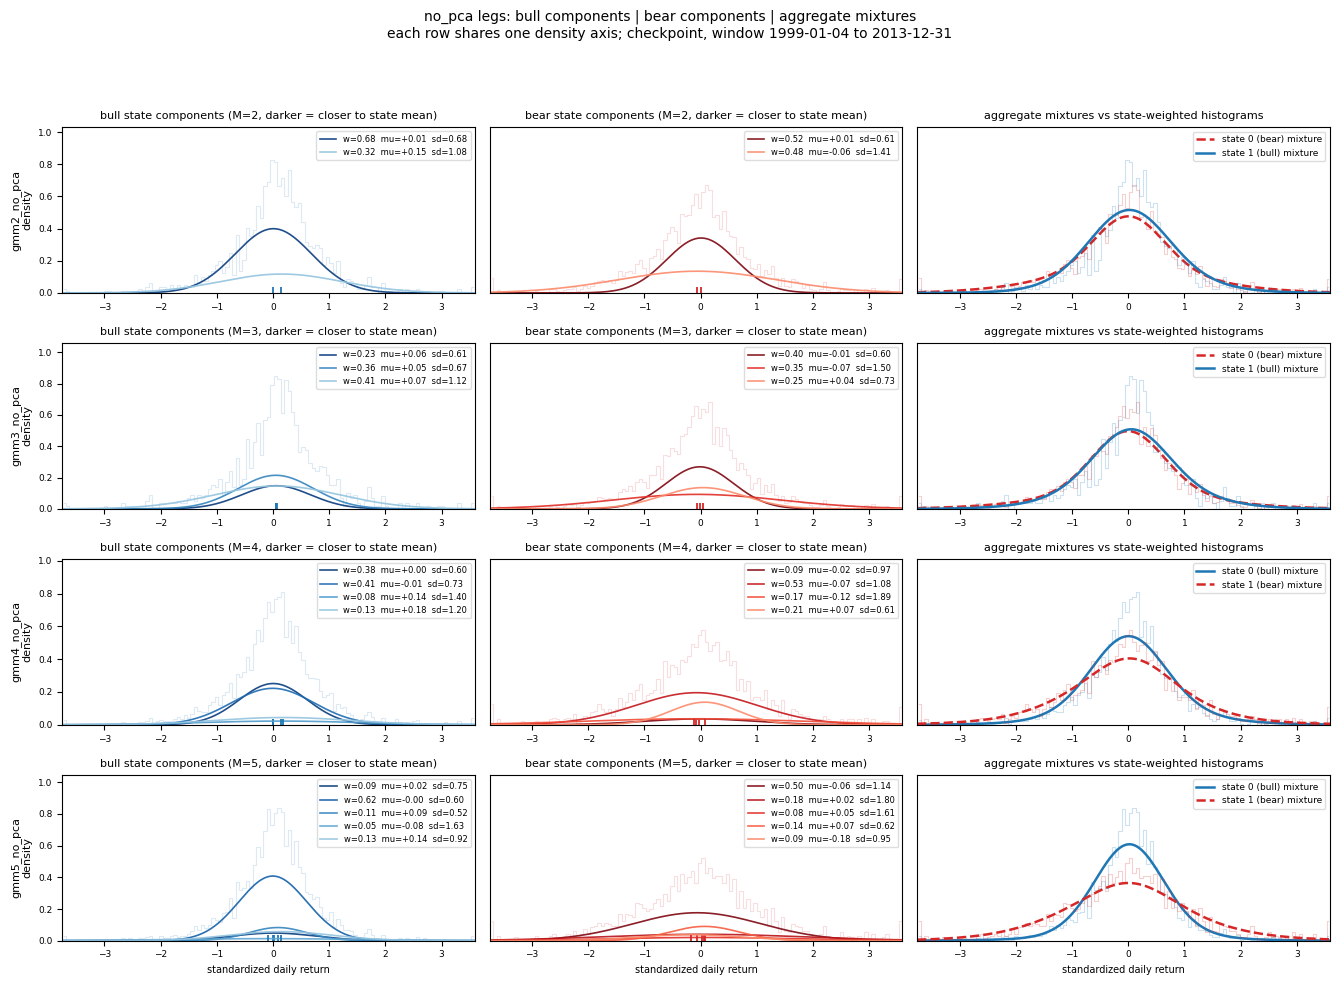

In [4]:
# Figure 1: per-spec component decomposition, bull components | bear components |
# aggregate. Component curves are w_j * N(mu_j, sd_j), so the M curves in a
# state panel sum exactly to that state's mixture curve in the third panel.
# Each row shares one density axis, sized to that row. One figure per leg.
import matplotlib.cm as cm
import matplotlib.colors as mcolors


def plot_leg_decomposition(keys, xlabel, title):
    """Draw one 3-column row per spec: bull components, bear, aggregate.

    Args:
        keys: Spec keys to plot, one per row, in display order.
        xlabel: Label naming the plotted feature (column 0 of model input).
        title: Figure suptitle text.
    """
    fig, axes = plt.subplots(len(keys), 3, figsize=(13.5, 2.5 * len(keys)))
    for row, key in zip(axes, keys):
        obs0 = curves[(key, 0)]["obs"]
        lo, hi = np.quantile(obs0, 0.004), np.quantile(obs0, 0.996)
        bins = np.linspace(lo, hi, 120)
        dx = bins[1] - bins[0]
        grid = curves[(key, 0)]["grid"]
        m = int(diag.loc[diag.spec == key, "M"].iloc[0])
        per_state = {}
        for k in (0, 1):
            s = diag[(diag.spec == key) & (diag.state == k)].iloc[0]
            c = curves[(key, k)]
            cs = comps[(comps.spec == key) & (comps.state == k)]
            per_state[k] = dict(
                base=np.array(mcolors.to_rgb("tab:blue" if s["bull"] else "tab:red")),
                bull=bool(s["bull"]), mix=c["pdf"],
                hist=np.histogram(np.clip(c["obs"], lo, hi), bins=bins,
                                  weights=c["weights"])[0]
                     / (c["weights"].sum() * dx),
                w=cs["weight"].to_numpy(), mu=cs["mu"].to_numpy(),
                sd=cs["sd"].to_numpy())
        ylim = max(max(s["mix"].max(), s["hist"].max())
                   for s in per_state.values()) * 1.25
        bull_k = next(k for k in (0, 1) if per_state[k]["bull"])
        for col, k in ((0, bull_k), (1, 1 - bull_k)):
            ax, s = row[col], per_state[k]
            cmap = cm.Blues if s["bull"] else cm.Reds
            center = (s["w"] * s["mu"]).sum()
            order = np.argsort(np.abs(s["mu"] - center))
            shades = cmap(np.linspace(0.95, 0.40, m))
            ax.step(0.5 * (bins[1:] + bins[:-1]), s["hist"], where="mid",
                    color=s["base"], alpha=0.15, lw=0.8)
            for rank, j in enumerate(order):
                ax.plot(grid, s["w"][j] * norm.pdf(grid, s["mu"][j], s["sd"][j]),
                        color=shades[rank], lw=1.2, alpha=0.9,
                        label=f"w={s['w'][j]:.2f}  mu={s['mu'][j]:+.2f}  "
                              f"sd={s['sd'][j]:.2f}")
                ax.plot([s["mu"][j]], [0.0], "|", color=s["base"], ms=8, mew=1.3)
            ax.set_ylim(0, ylim)
            ax.set_xlim(lo, hi)
            ax.set_title(f"{'bull' if s['bull'] else 'bear'} state components "
                         f"(M={m}, darker = closer to state mean)", fontsize=8)
            ax.legend(fontsize=6, loc="upper right", framealpha=0.65)
            ax.tick_params(labelsize=6.5)
        ax = row[2]
        for k in (0, 1):
            s = per_state[k]
            ax.plot(grid, s["mix"], color=s["base"], lw=1.8,
                    linestyle="-" if s["bull"] else "--",
                    label=f"state {k} ({'bull' if s['bull'] else 'bear'}) mixture")
            ax.step(0.5 * (bins[1:] + bins[:-1]), s["hist"], where="mid",
                    color=s["base"], alpha=0.22, lw=0.8)
        ax.set_ylim(0, ylim)
        ax.set_xlim(lo, hi)
        ax.set_title("aggregate mixtures vs state-weighted histograms", fontsize=8)
        ax.legend(fontsize=6.5, loc="upper right", framealpha=0.65)
        ax.tick_params(labelsize=6.5)
        row[0].set_ylabel(f"{key}\ndensity", fontsize=8)
        for ax in row[1:]:
            ax.tick_params(axis="y", labelleft=False, left=False)
    for ax in axes[-1]:
        ax.set_xlabel(xlabel, fontsize=7)
    fig.suptitle(title + "\neach row shares one density axis; checkpoint, window "
                 f"{hist[0].date()} to {hist[-1].date()}", fontsize=10)
    fig.tight_layout(rect=[0, 0, 1, 0.94])


plot_leg_decomposition(
    sorted(diag.loc[diag.leg == "no_pca", "spec"].unique(),
           key=lambda key: int(key[3])),
    "standardized daily return",
    "no_pca legs: bull components | bear components | aggregate mixtures")
plt.show()


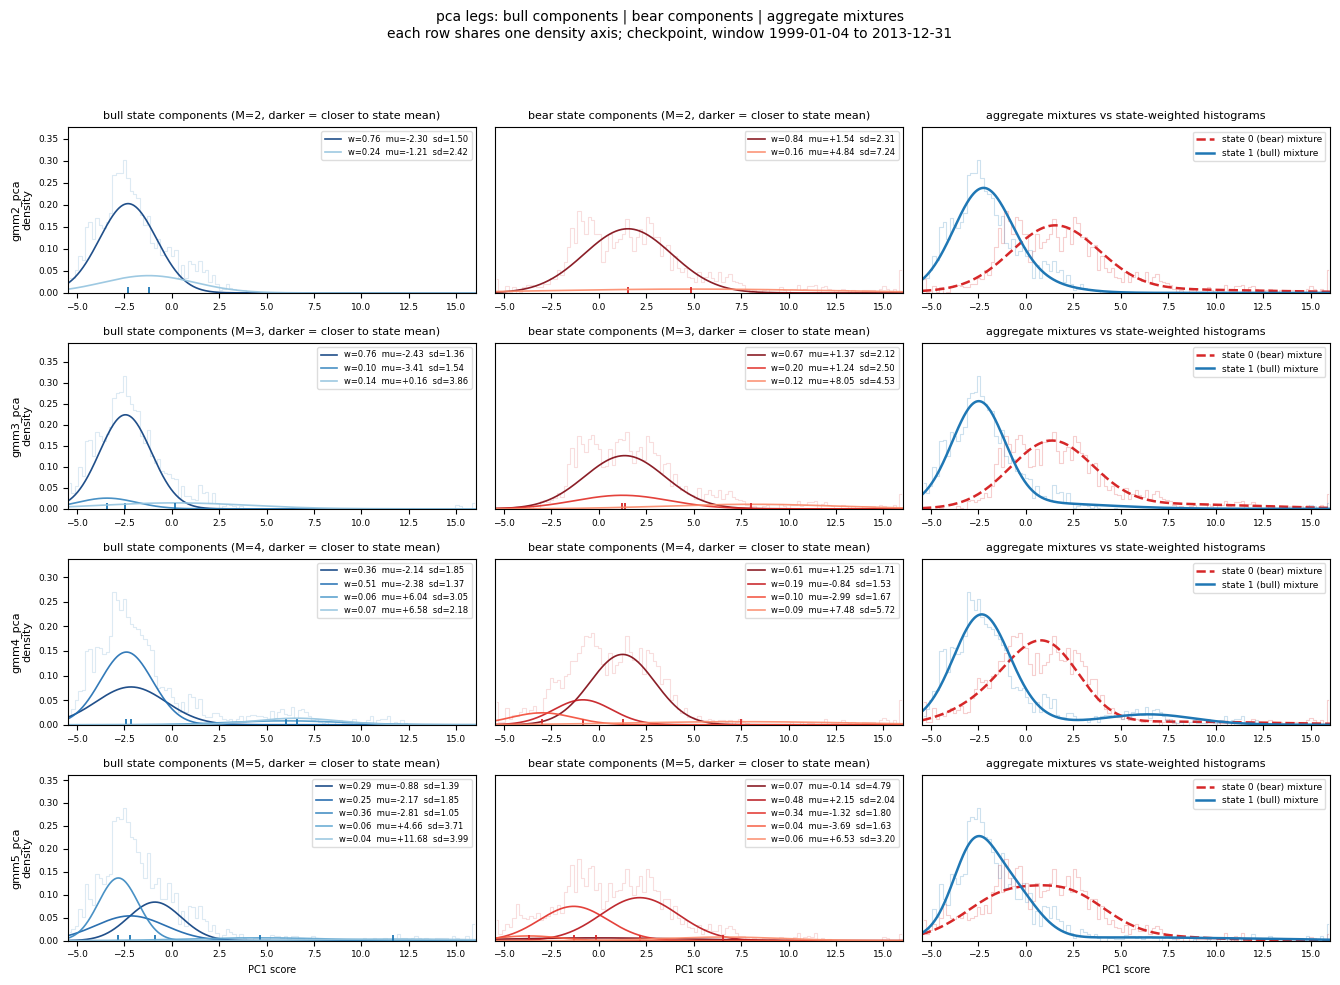

In [5]:
plot_leg_decomposition(
    sorted(diag.loc[diag.leg == "pca", "spec"].unique(),
           key=lambda key: int(key[3])),
    "PC1 score",
    "pca legs: bull components | bear components | aggregate mixtures")
plt.show()


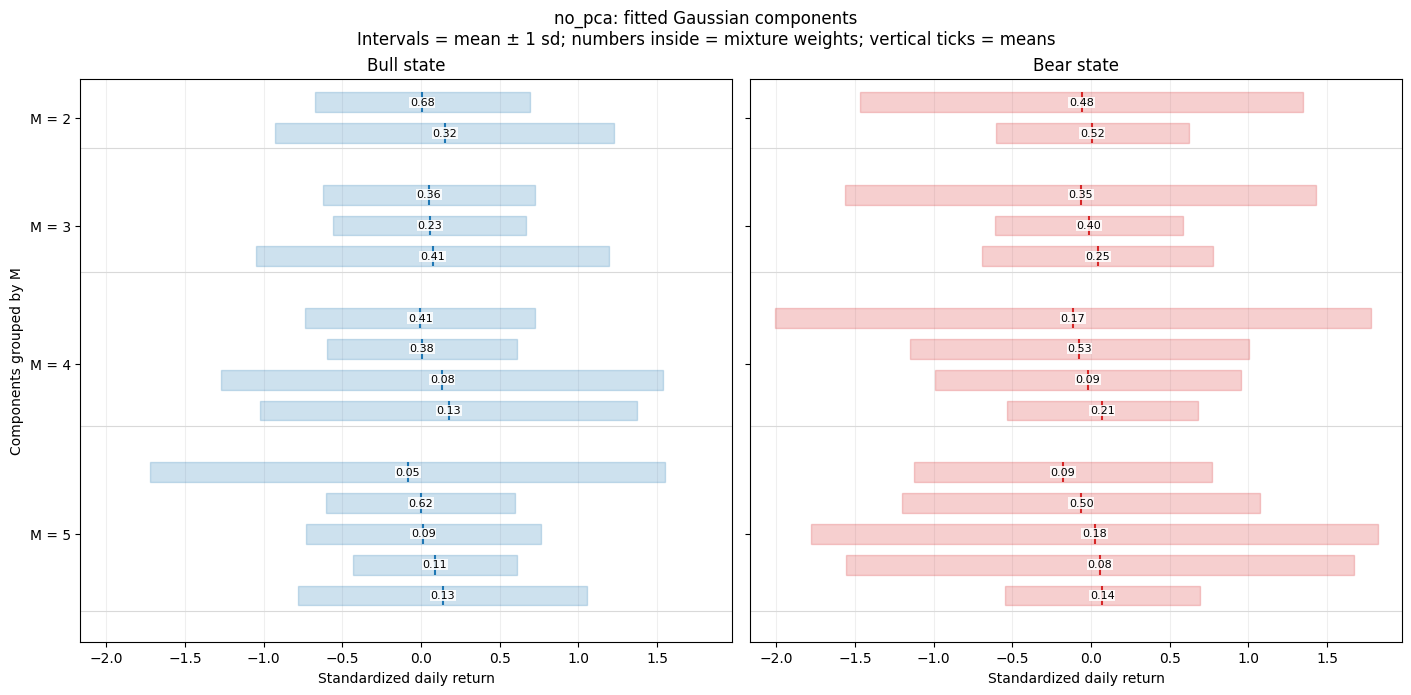

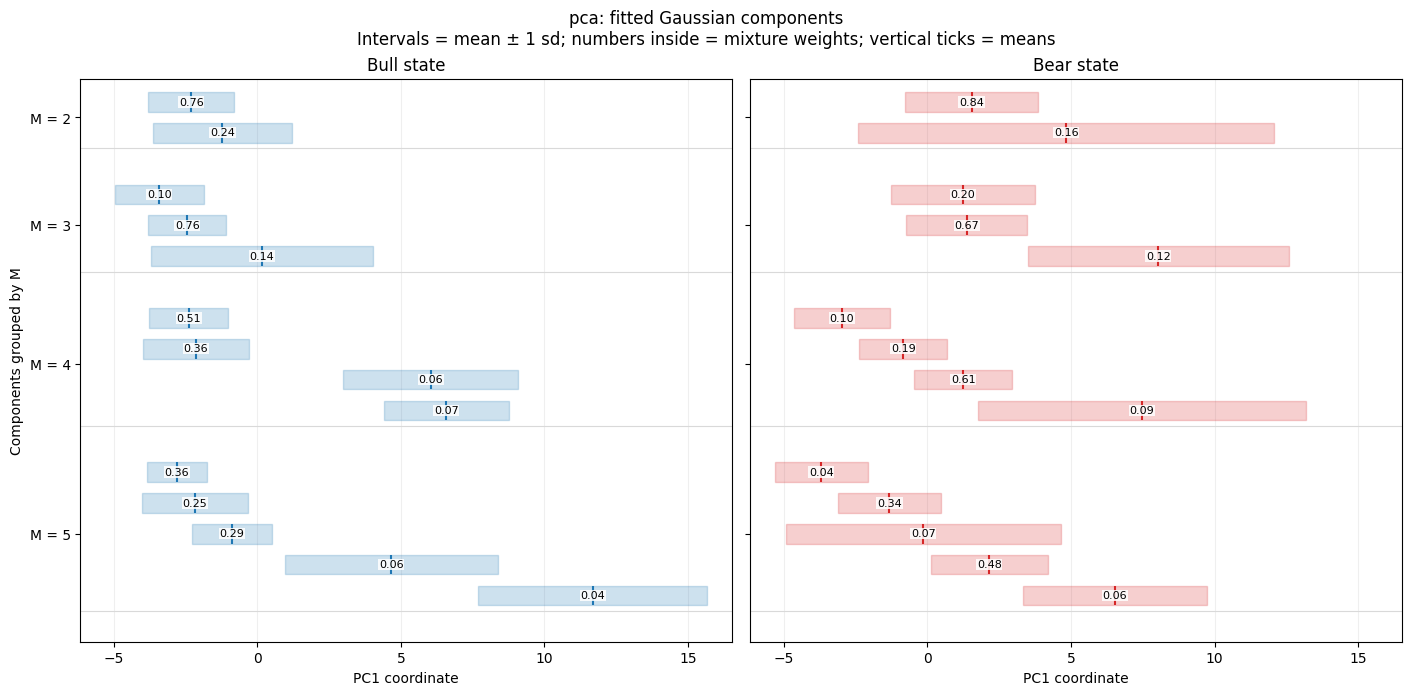

In [5]:
from matplotlib.patches import Rectangle

# One component per row; interval = mean ± sd; label = mixture weight.
for leg in ("no_pca", "pca"):
    keys = [
        key for key in SPEC_ORDER
        if diag.loc[diag["spec"] == key, "leg"].iloc[0] == leg
    ]
    keys = sorted(
        keys,
        key=lambda key: int(diag.loc[diag["spec"] == key, "M"].iloc[0]),
    )

    total_rows = sum(
        int(diag.loc[diag["spec"] == key, "M"].iloc[0])
        for key in keys
    )
    figure_height = max(6, 0.38 * (total_rows + len(keys)))

    fig, axes = plt.subplots(
        1, 2,
        figsize=(14, figure_height),
        sharex=True,
        sharey=True,
        layout="constrained",
    )

    for ax, is_bull, color in (
        (axes[0], True, "tab:blue"),
        (axes[1], False, "tab:red"),
    ):
        y = 0
        tick_positions = []
        tick_labels = []

        for key in keys:
            model_diag = diag.loc[diag["spec"] == key]
            state_row = model_diag.loc[
                model_diag["bull"] == is_bull
            ].iloc[0]
            m = int(state_row["M"])

            components = comps.loc[
                (comps["spec"] == key)
                & (comps["state"] == state_row["state"])
            ].sort_values("mu")

            group_start = y

            for _, component in components.iterrows():
                mean = float(component["mu"])
                sd = float(component["sd"])
                weight = float(component["weight"])
                left = mean - sd

                # Filled interval with fixed height, not a confidence interval.
                ax.add_patch(Rectangle(
                    (left, y - 0.32),
                    width=2 * sd,
                    height=0.64,
                    facecolor=color,
                    edgecolor=color,
                    alpha=0.22,
                    linewidth=1,
                ))

                # Mark the component mean.
                ax.vlines(
                    mean, y - 0.32, y + 0.32,
                    color=color, linewidth=1.5,
                )

                # Weight inside its own interval.
                ax.text(
                    mean, y,
                    f"{weight:.2f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="black",
                    bbox={
                        "facecolor": "white",
                        "edgecolor": "none",
                        "alpha": 0.85,
                        "pad": 0.5,
                    },
                )
                y += 1

            tick_positions.append((group_start + y - 1) / 2)
            tick_labels.append(f"M = {m}")

            ax.axhline(y - 0.5, color="0.85", linewidth=0.8)
            y += 1  # Gap between component-count groups.

        ax.set_yticks(tick_positions, tick_labels)
        ax.set_title("Bull state" if is_bull else "Bear state")
        ax.set_xlabel(
            "Standardized daily return"
            if leg == "no_pca"
            else "PC1 coordinate"
        )
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)

    # Common limits include every component's full displayed interval.
    sub = comps.loc[comps["leg"] == leg]
    lower = (sub["mu"] - sub["sd"]).min()
    upper = (sub["mu"] + sub["sd"]).max()
    padding = max(0.04 * (upper - lower), 0.1)

    axes[0].set_xlim(lower - padding, upper + padding)
    axes[0].set_ylim(y - 0.5, -0.75)
    axes[0].set_ylabel("Components grouped by M")

    fig.suptitle(
        f"{leg}: fitted Gaussian components\n"
        "Intervals = mean ± 1 sd; numbers inside = mixture weights; "
        "vertical ticks = means",
        fontsize=12,
    )
    plt.show()

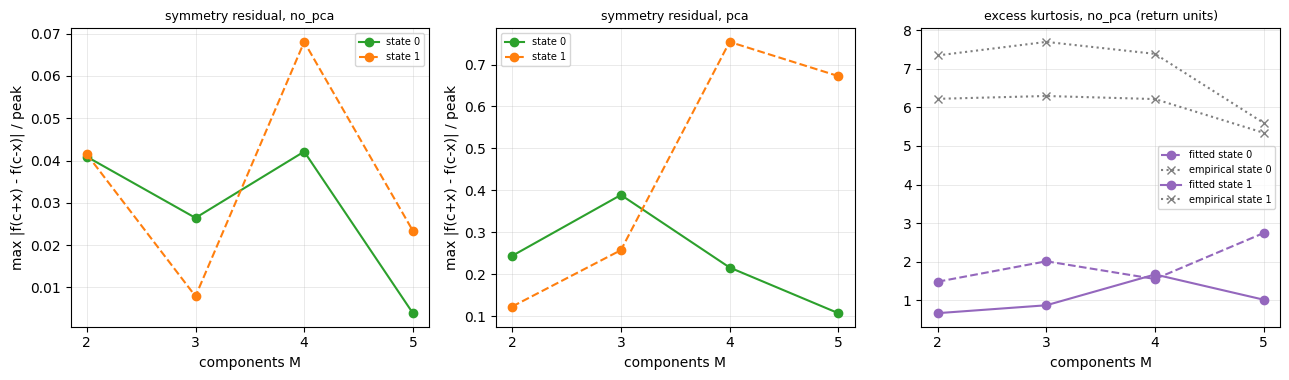

In [7]:
# Figure 3: symmetry residual by M per leg, and fitted vs empirical excess
# kurtosis on the no_pca leg.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, leg in zip(axes[:2], ("no_pca", "pca")):
    sub = diag[diag.leg == leg]
    for k, style in zip((0, 1), ("-", "--")):
        s = sub[sub.state == k].sort_values("M")
        ax.plot(s.M, s.sym, style, marker="o", label=f"state {k}",
                color="tab:green" if k == 0 else "tab:orange")
    ax.set_title(f"symmetry residual, {leg}", fontsize=9)
    ax.set_xlabel("components M")
    ax.set_xticks([2, 3, 4, 5])
    ax.set_ylabel("max |f(c+x) - f(c-x)| / peak")
    ax.grid(alpha=0.3, lw=0.6)
    ax.legend(fontsize=7)
sub = diag[diag.leg == "no_pca"]
for k in (0, 1):
    s = sub[sub.state == k].sort_values("M")
    axes[2].plot(s.M, s.exkurt, marker="o", ls="-" if k else "--",
                 label=f"fitted state {k}", color="tab:purple")
    axes[2].plot(s.M, s.emp_exkurt, marker="x", ls=":", label=f"empirical state {k}",
                 color="tab:gray")
axes[2].set_title("excess kurtosis, no_pca (return units)", fontsize=9)
axes[2].set_xlabel("components M")
axes[2].set_xticks([2, 3, 4, 5])
axes[2].grid(alpha=0.3, lw=0.6)
axes[2].legend(fontsize=7)
fig.tight_layout()
plt.show()


## What the fitted components show

- The odd-M symmetry effect appears in the component layout on the no-PCA leg. With odd $M$ one component anchors the center: `gmm3_no_pca` bear puts a 0.40-weight component at +0.001%/day, `gmm5_no_pca` bull puts a 0.62-weight component at +0.015%/day. With even $M$ no component sits at the center, so EM splits it between a wide and a narrow component (e.g. `gmm2_no_pca` bear: 0.48 at -0.060%/1.83% against 0.52 at +0.030%/0.89%), a width-asymmetric pair.
- Parity table: on the no-PCA leg the odd-$M$ states are 5 to 10 times more symmetric (0.004 to 0.008 vs 0.041 to 0.042) with near-zero fitted skew. The PCA leg is mixed: odd $M$ wins KS, and $M=5$ wins symmetry, but $M=3$ is the least symmetric state there.
- All $M$ understate the tails: fitted excess kurtosis is 0.7 to 2.7; the filtered-posterior-weighted empirical histograms are 5.3 to 7.7. Components beyond a center plus one tail component (weight 0.04 to 0.13, sd 2 to 4x the state sd) chase tails without capturing their weight.
- $M \ge 4$ on the PCA leg is where the fit degrades: `gmm5_pca` bull has fitted skew 2.66, excess kurtosis 8.8, symmetry residual 0.67, driven by a 0.04-weight component at PC1 +11.7 (Figure 2, bottom panel). This matches the Sharpe collapse for $M=4,5$ in `gmm_sweep.ipynb`.

Caveats: single seed per spec and one training window; KS and the histograms are in-sample (fitted and scored on the same data), so they measure shape recovery, not generalization; the bars weight every day by its filtered posterior, so blue and red histograms overlap by construction. A parity claim from 4 specs and one seed is a pattern to test with seeds 1 and 2, not an established result.
